<h1>Hacker News Posts</h1>

<p> In this project we are exploring the dataset of Hacker news this is a website where technology related posts are upvoted and downvoted and commented on like reddit.</p>
<p>Our main goal is to compare the two types of post ask Hn and show Hn and determine</p>
<li>which ask Hn or show Hn types post receive more average comments ?</li>
<li>Do time and date affect the comments on these tyeps of posts ?</li>

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('hacker_news.csv')

In [3]:
df.head()

,id,title,url,num_points,num_comments,author,created_at
0,12224879,Interactive Dynamic Video,http://www.interactivedynamicvideo.com/,386,52,ne0phyte,8/4/2016 11:52
1,10975351,How to Use Open Source and Shut the Fuck Up at...,http://hueniverse.com/2016/01/26/how-to-use-op...,39,10,josep2,1/26/2016 19:30
2,11964716,Florida DJs May Face Felony for April Fools' W...,http://www.thewire.com/entertainment/2013/04/f...,2,1,vezycash,6/23/2016 22:20
3,11919867,Technology ventures: From Idea to Enterprise,https://www.amazon.com/Technology-Ventures-Ent...,3,1,hswarna,6/17/2016 0:01
4,10301696,Note by Note: The Making of Steinway L1037 (2007),http://www.nytimes.com/2007/11/07/movies/07ste...,8,2,walterbell,9/30/2015 4:12


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20100 entries, 0 to 20099
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            20100 non-null  int64 
 1   title         20100 non-null  object
 2   url           17660 non-null  object
 3   num_points    20100 non-null  int64 
 4   num_comments  20100 non-null  int64 
 5   author        20100 non-null  object
 6   created_at    20100 non-null  object
dtypes: int64(3), object(4)
memory usage: 1.1+ MB


In [3]:
df['created_at'] = pd.to_datetime(df['created_at'])

In [8]:
df['created_at'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 20100 entries, 0 to 20099
Series name: created_at
Non-Null Count  Dtype         
--------------  -----         
20100 non-null  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 157.2 KB


In [9]:
df['created_at'].head(2)

0   2016-08-04 11:52:00
1   2016-01-26 19:30:00
Name: created_at, dtype: datetime64[ns]

In [10]:
df.isna().sum()

id                 0
title              0
url             2440
num_points         0
num_comments       0
author             0
created_at         0
dtype: int64

In [4]:
df.drop('url', axis = 1, inplace = True)

In [5]:
df.head(2)

,id,title,num_points,num_comments,author,created_at
0,12224879,Interactive Dynamic Video,386,52,ne0phyte,2016-08-04 11:52:00
1,10975351,How to Use Open Source and Shut the Fuck Up at...,39,10,josep2,2016-01-26 19:30:00


In [15]:
df.duplicated().sum()

0

<h3>Extracting ask Hn and show Hn posts</h3>

In [6]:
def categ_post(title):
    if 'ask hn' in title.lower():
        return 'ask hn'
    elif 'show hn' in title.lower():
        return 'show hn'
    else:
        return 'other'

df['post_type'] = df['title'].apply(categ_post)

In [7]:
df['post_type'].value_counts()

post_type
other      17190
ask hn      1745
show hn     1165
Name: count, dtype: int64

<h3>Calculating the average number of comments on ask Hn and show Hn posts</h3>

In [10]:
avg_com = df.groupby(df['post_type'])['num_comments'].mean().reset_index()
avg_com

,post_type,num_comments
0,ask hn,14.031519
1,other,26.878360
2,show hn,10.302146


Text(0.5, 1.0, 'Comments on Types of Posts on Hacker News')

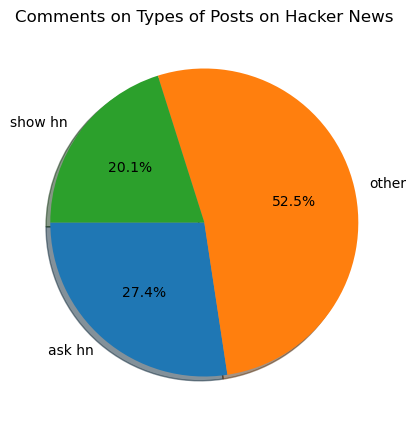

In [18]:
plt.figure(figsize = (5,5))
plt.pie(avg_com['num_comments'], labels = avg_com['post_type'],startangle = 180, autopct = '%1.1f%%',shadow = True)
plt.title('Comments on Types of Posts on Hacker News')

In [27]:
df['hour_of_day'] = df['created_at'].dt.hour
df.head()

,id,title,num_points,num_comments,author,created_at,post_type,hour_of_day
0,12224879,Interactive Dynamic Video,386,52,ne0phyte,2016-08-04 11:52:00,other,11
1,10975351,How to Use Open Source and Shut the Fuck Up at...,39,10,josep2,2016-01-26 19:30:00,other,19
2,11964716,Florida DJs May Face Felony for April Fools' W...,2,1,vezycash,2016-06-23 22:20:00,other,22
3,11919867,Technology ventures: From Idea to Enterprise,3,1,hswarna,2016-06-17 00:01:00,other,0
4,10301696,Note by Note: The Making of Steinway L1037 (2007),8,2,walterbell,2015-09-30 04:12:00,other,4


In [32]:
ask_com = df[df['post_type'] == 'ask hn']
ask_com.head()

,id,title,num_points,num_comments,author,created_at,post_type,hour_of_day
7,12296411,Ask HN: How to improve my personal website?,2,6,ahmedbaracat,2016-08-16 09:55:00,ask hn,9
17,10610020,Ask HN: Am I the only one outraged by Twitter ...,28,29,tkfx,2015-11-22 13:43:00,ask hn,13
22,11610310,Ask HN: Aby recent changes to CSS that broke m...,1,1,polskibus,2016-05-02 10:14:00,ask hn,10
30,12210105,Ask HN: Looking for Employee #3 How do I do it?,1,3,sph130,2016-08-02 14:20:00,ask hn,14
31,10394168,Ask HN: Someone offered to buy my browser exte...,28,17,roykolak,2015-10-15 16:38:00,ask hn,16


In [43]:
ask_com_hr = ask_com.groupby(ask_com.hour_of_day)['num_comments'].sum().reset_index()
ask_com_hr

,hour_of_day,num_comments
0,0,447
1,1,683
2,2,1381
3,3,421
4,4,337
5,5,464
6,6,397
7,7,267
8,8,492
9,9,251


[Text(0.5, 0, 'Hour of Day'),
 Text(0, 0.5, 'Number of Comments'),
 Text(0.5, 1.0, 'Number of Comments Received by "ask Hn posts" Hourly')]

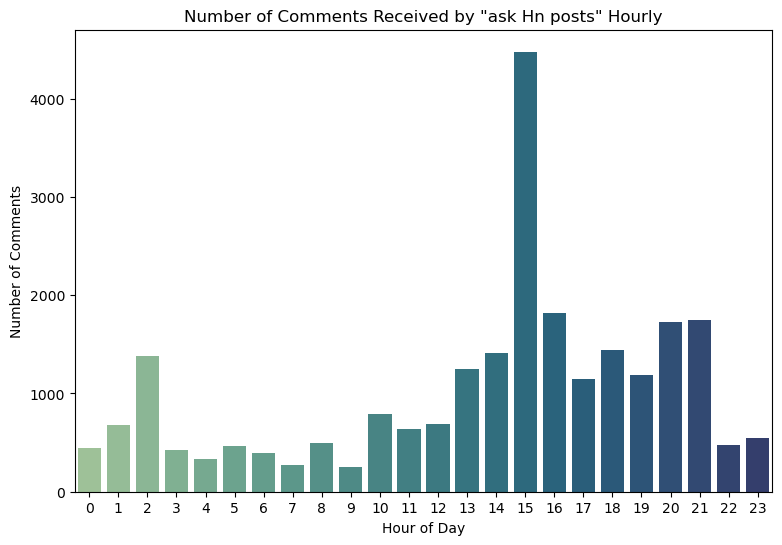

In [59]:
plt.figure(figsize = (9,6))
viz_1 = sns.barplot(ask_com_hr, x = 'hour_of_day', y = 'num_comments', palette = 'crest')
viz_1.set(xlabel = 'Hour of Day', ylabel = 'Number of Comments',title = 'Number of Comments Received by "ask Hn posts" Hourly')

In [63]:
avg_ask_com = ask_com.groupby(ask_com.hour_of_day)['num_comments'].mean().reset_index()
avg_ask_com.sort_values(by = 'num_comments', ascending = False).head(5)

,hour_of_day,num_comments
15,15,38.594828
2,2,23.810345
20,20,21.525000
16,16,16.796296
21,21,16.009174
